# TuniShop — 01. EDA globale : données, qualité, vue d'ensemble

**Auteure :** Sarra Abdeljaouad · **Source :** TuniShop_DWH, lecture directe des vues `bi` (SQL Server) · **Période :** 01/01/2023 – 31/12/2025

## Rôle de ce notebook

C'est le **point d'entrée** de toute l'analyse. Il :
1. se connecte au DWH et vérifie que les 23 vues sont complètes (contrôles C01-C02) ;
2. vérifie que les données sont celles du DWH validé (C03-C07) ;
3. contrôle leur qualité : intégrité, doublons, membres techniques, valeurs manquantes, valeurs extrêmes (C08-C11) ;
4. donne une **vue d'ensemble** de l'activité avant les analyses thématiques ;
5. construit les **4 tables de variables** communes au data mining et au ML (`05_Data/features`) et leurs métadonnées.

Il produit aussi le fichier `04_Livrables/EDA/Rapport_Qualite_Analytique.xlsx`.

## Organisation de l'EDA

| Notebook | Questions (Plan_Analyse_EDA) | Thème |
|---|---|---|
| **01_EDA_Global** | contrôles C01 à C11 | données, qualité, vue d'ensemble, tables de variables |
| 02_EDA_Sales | Q1, Q2, Q9 | évolution des ventes, saisonnalité, canaux et modes de paiement |
| 03_EDA_Customers | Q5, Q6, Q7, Q8, Q15, Q18 | clients, fidélité, géographie, satisfaction |
| 04_EDA_Products | Q3, Q4, Q16 | catégories, concentration, gammes, retours |
| 05_EDA_Stock_Logistics | Q13, Q14, Q19, Q20, Q21 | livraison, entrepôts, stock, fournisseurs |
| 06_EDA_Marketing_Finance | Q10, Q11, Q12, Q17 | paiements, campagnes, coupons, remboursements |

**Ordre d'exécution :** 01_EDA_Global d'abord (il crée les tables de `05_Data`), puis les 5 autres dans n'importe quel ordre.

## Liaison directe avec le DWH

| Façon | Outil | Quand |
|---|---|---|
| **Requête SQL** exécutée par SQL Server | `sql("SELECT ... FROM bi.v_...")` | agrégats simples : totaux, taux, moyennes par groupe |
| **pandas** sur les vues chargées | `p["cmd"]`, `p["lig"]`... | distributions, cohortes, corrélations, tables de variables |

Deux habitudes T-SQL utilisées dans toutes les requêtes : `1.0 * SUM(...) / COUNT(*)` pour éviter la division entière, et `SUM(CASE WHEN colonne_bit = 1 THEN 1 ELSE 0 END)` car une colonne BIT ne s'additionne pas.

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun, à côté de ce dossier)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, validation, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)      # messages de version sans intérêt ici
cfg.appliquer_style()

# --- Raccourcis
sql = chargement.requete                                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

## 1. Connexion et inventaire des vues (C01, C02)

On ouvre la connexion, puis SQL Server compte les lignes et les colonnes de chaque vue. On compare au nombre de lignes du DWH validé.

In [2]:
chargement.ouvrir_connexion()                                   # C01 : message « Connecté à ... »
inventaire = validation.controle_inventaire(chargement.inventaire_vues())   # C02
inventaire

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)


,vue,type,lignes,colonnes,lignes_attendues,ecart,statut
0,bi.v_dim_date,dimension,1828,17,1828,0,OK
1,bi.v_dim_client,dimension,16002,20,16002,0,OK
2,bi.v_dim_produit,dimension,1603,20,1603,0,OK
3,bi.v_dim_fournisseur,dimension,42,9,42,0,OK
4,bi.v_dim_geographie,dimension,26,8,26,0,OK
5,bi.v_dim_entrepot,dimension,5,8,5,0,OK
6,bi.v_dim_transporteur,dimension,6,6,6,0,OK
7,bi.v_dim_campagne,dimension,154,11,154,0,OK
8,bi.v_dim_coupon,dimension,70,7,70,0,OK
9,bi.v_dim_canal,dimension,8,5,8,0,OK


> **Lecture.** Les **23 vues** sont présentes et ont **exactement** le nombre de lignes du DWH validé (contrôles C01 et C02 : OK). Si l'Agent SQL recharge le DWH avec de nouvelles données, ce tableau le montrera en premier (colonne `ecart`).

## 2. Chargement et point de départ contrôlé (C03 à C07)

Les 23 vues sont lues en direct, puis préparées par `tunishop_kpi.preparer()` (jointures aux dimensions, colonnes d'analyse). Cinq totaux sont ensuite comparés de trois façons : la valeur des **procès-verbaux** (DWH 28/10/2026, cubes 04/11/2026), le calcul fait **par SQL Server** sur les vues, et le calcul **Python** sur les tables chargées.

In [3]:
vues, p = chargement.charger_donnees(source="dwh")
cmd, lig, liv, avis, rmb, pai = p["cmd"], p["lig"], p["liv"], p["avis"], p["rmb"], p["pai"]

Lecture directe des vues bi.v_* — 13/11/2026 23:39
  v_dim_date                        1 828 lignes


  v_dim_client                     16 002 lignes
  v_dim_produit                     1 603 lignes
  v_dim_fournisseur                    42 lignes
  v_dim_geographie                     26 lignes
  v_dim_entrepot                        5 lignes
  v_dim_transporteur                    6 lignes
  v_dim_campagne                      154 lignes
  v_dim_coupon                         70 lignes
  v_dim_canal                           8 lignes
  v_dim_mode_paiement                   7 lignes
  v_dim_statut_commande                10 lignes
  v_dim_motif_retour                   14 lignes


  v_fact_ventes                   115 903 lignes


  v_fact_commandes                 66 268 lignes


  v_fact_paiements                 64 491 lignes


  v_fact_livraisons                61 793 lignes
  v_fact_remboursements             8 815 lignes


  v_fact_avis                       9 314 lignes
  v_fact_marketing_quotidien        3 427 lignes


  v_fact_achats_fournisseur        11 793 lignes


  v_fact_mouvements_stock         140 184 lignes


  v_fact_stock_mensuel             56 562 lignes


In [4]:
coherence = validation.verifier_coherence(p)
coherence

,controle,indicateur,valide_pv,sql_vues_bi,python_pandas,statut
0,C03,Lignes de vente,115 903.000,115 903.000,115 903.000,OK
1,C04,Commandes,66 268.000,66 268.000,66 268.000,OK
2,C05,Livraisons,61 793.000,61 793.000,61 793.000,OK
3,C06,CA reconnu TTC (DT),15 541 665.655,15 541 665.655,15 541 665.655,OK
4,C07,Clients ayant commandé (hors membre inconnu),12 472.000,12 472.000,12 472.000,OK


> **Lecture.** Les 5 totaux sont **identiques** de trois façons : procès-verbal, calcul de SQL Server et calcul Python (C03 à C07 : OK). La lecture directe n'a donc rien perdu ni dupliqué, et le DWH est bien celui qui a été validé : toute l'analyse part d'une base contrôlée.

## 3. Qualité des données (C08 à C11)

### 3.1 Intégrité référentielle (C08) — 🔗 SQL direct

Pour 16 relations « fait → dimension », SQL Server compte les lignes de faits dont la clé ne retrouve pas sa dimension (`LEFT JOIN` puis `IS NULL`). Une ligne inconnue doit pointer vers le membre -1, pas vers rien.

In [5]:
integrite = validation.integrite_referentielle()
integrite

,fait,cle,dimension,lignes,orphelines,statut
0,v_fact_ventes,produit_sk,v_dim_produit,115903,0,OK
1,v_fact_ventes,date_commande_sk,v_dim_date,115903,0,OK
2,v_fact_commandes,client_sk,v_dim_client,66268,0,OK
3,v_fact_commandes,canal_sk,v_dim_canal,66268,0,OK
4,v_fact_commandes,statut_commande_sk,v_dim_statut_commande,66268,0,OK
5,v_fact_commandes,coupon_sk,v_dim_coupon,66268,0,OK
6,v_fact_paiements,mode_paiement_sk,v_dim_mode_paiement,64491,0,OK
7,v_fact_livraisons,transporteur_sk,v_dim_transporteur,61793,0,OK
8,v_fact_livraisons,geographie_sk,v_dim_geographie,61793,0,OK
9,v_fact_livraisons,entrepot_sk,v_dim_entrepot,61793,0,OK


> **Lecture.** Les 16 relations testées ont **0 ligne orpheline** (C08 : OK) : chaque commande retrouve son client, chaque ligne son produit, chaque livraison son transporteur, etc. Les données sans correspondance pointent bien vers le membre « inconnu » (-1) au lieu de disparaître.

### 3.2 Unicité des clés (C09)

In [6]:
unicite = validation.unicite(p)
unicite

,table,cle,lignes,doublons,statut
0,cmd,commande_id,66268,0,OK
1,lig,ligne_id,115903,0,OK
2,liv,livraison_id,61793,0,OK
3,rmb,remboursement_id,8815,0,OK
4,avis,avis_id,9314,0,OK
5,pai,paiement_id,64491,0,OK


> **Lecture.** Aucune des 6 tables de faits n'a de doublon sur sa clé (C09 : OK). Les comptages de l'EDA (commandes, livraisons, avis...) ne sont donc pas gonflés.

### 3.3 Membres techniques (C10)

-1 = **inconnu** (aucune correspondance trouvée au chargement) ; -2 = **non applicable** (par exemple : pas de coupon, pas encore expédiée). Seul -1 signale un défaut de qualité.

In [7]:
membres = validation.membres_techniques(p)
membres

,colonne,inconnu_-1,non_applicable_-2,part_-1,part_-2,statut
0,client_sk,25,0,0.000,0.000,OK
1,geographie_sk,0,0,0.000,0.000,OK
2,canal_sk,0,0,0.000,0.000,OK
3,campagne_sk,0,46883,0.000,0.707,OK
4,coupon_sk,0,60627,0.000,0.915,OK
5,mode_paiement_sk,0,0,0.000,0.000,OK
6,date_expedition_sk,0,4525,0.000,0.068,OK
7,date_livraison_sk,0,7492,0.000,0.113,OK


> **Lecture.** Les membres « inconnu » (-1) sont **rares** : 25 commandes seulement ont un client inconnu (0,04 %). Les valeurs « non applicable » (-2) sont une information, pas une erreur : 71 % des commandes sans campagne, 91 % sans coupon, 6,8 % jamais expédiées et 11,3 % jamais livrées (C10 : OK). **Pour le ML :** on les transforme en variables explicites (par exemple `a_coupon` = 0/1), on ne les traite jamais comme des nombres.

### 3.4 Valeurs manquantes (C11)

Un vide n'est pas forcément une erreur : il faut une **explication métier** pour chacun.

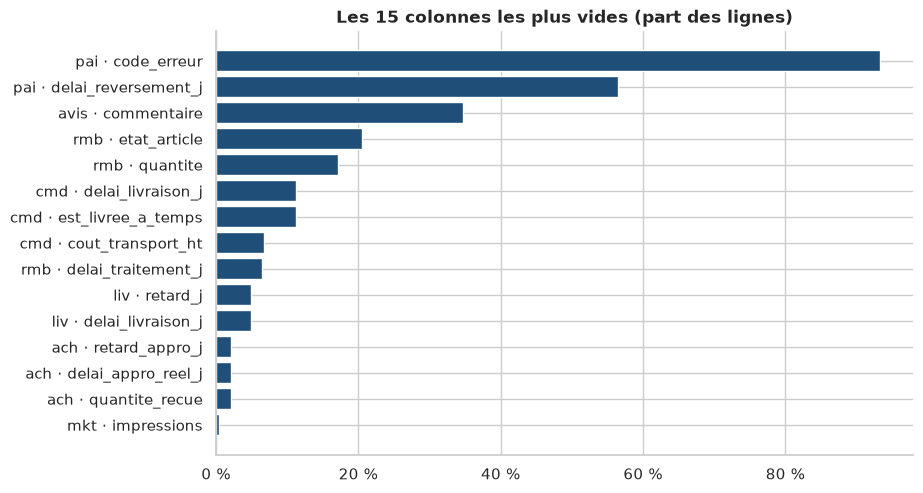

,table,colonne,lignes,vides,part_vide,statut
0,pai,code_erreur,64491,60193,0.933,INFO
1,pai,delai_reversement_j,64491,36435,0.565,INFO
2,avis,commentaire,9314,3233,0.347,INFO
3,rmb,etat_article,8815,1815,0.206,INFO
4,rmb,quantite,8815,1507,0.171,INFO
5,cmd,delai_livraison_j,66268,7492,0.113,INFO
6,cmd,est_livree_a_temps,66268,7492,0.113,INFO
7,cmd,cout_transport_ht,66268,4475,0.068,INFO
8,rmb,delai_traitement_j,8815,569,0.065,INFO
9,liv,retard_j,61793,3017,0.049,INFO


In [8]:
manquants = validation.valeurs_manquantes(p)

fig, ax = plt.subplots(figsize=(9, 5.5))
m_ = manquants.head(15).iloc[::-1]
ax.barh(m_["table"] + " · " + m_["colonne"], m_["part_vide"], color=cfg.BLEU)
ax.set_title("Les 15 colonnes les plus vides (part des lignes)"); cfg.format_pourcent(ax, "x")
montrer("G01_valeurs_manquantes")
manquants

> **Lecture.** 21 colonnes ont des vides, et **chacun a une explication métier** (C11 : expliqué) : le code d'erreur n'existe que pour les paiements échoués (93 % de vides), le délai de reversement que pour le paiement à la livraison (57 %), le commentaire d'avis est facultatif (35 %), l'état de l'article est sans objet pour une annulation (21 %), le délai de livraison est vide pour les 11,3 % de commandes non livrées. L'explication de chaque colonne est écrite dans le Rapport_Qualite_Analytique. **Pour le ML :** on ne remplace jamais ces vides par 0 sans réfléchir (un délai de 0 jour n'est pas « pas de livraison ») : on filtre la population ou on ajoute un indicateur.

### 3.5 Valeurs extrêmes

Règle de Tukey : une valeur est « très extrême » au-delà de Q3 + 3 × (Q3 − Q1). On ne supprime rien (ces valeurs sont réelles), mais on en tient compte dans le choix des modèles.

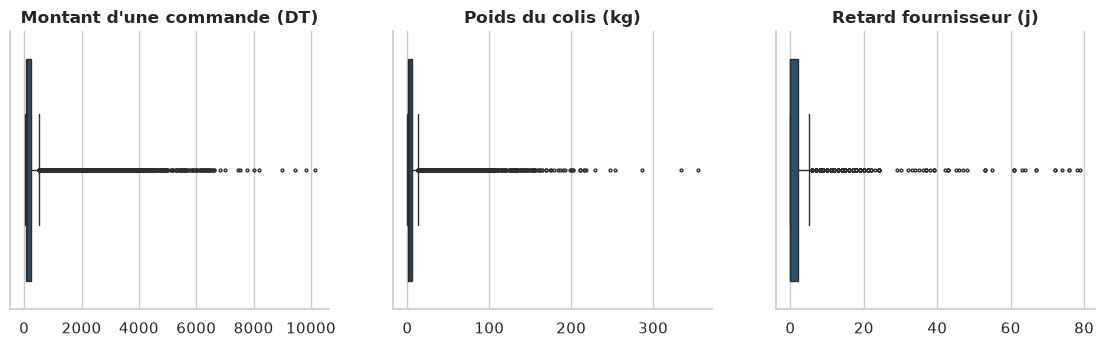

,table,variable,libelle,valeurs,mediane,q3,seuil_haut,maximum,nb_extremes,part_extremes,statut
0,cmd,montant_total_ttc,Montant d'une commande (DT),66268,114.900,242.800,815.500,10 126.300,4617,0.070,INFO
1,cmd,nb_articles,Articles par commande,66268,2.000,3.000,9.000,101.000,2011,0.030,INFO
2,liv,delai_livraison_j,Délai de livraison (j),58776,3.210,4.220,9.590,13.130,99,0.002,INFO
3,liv,delai_preparation_h,Préparation (h),61743,17.970,23.970,66.030,170.470,927,0.015,INFO
4,liv,poids_kg,Poids du colis (kg),61793,2.130,5.870,21.020,354.270,3041,0.049,INFO
5,rmb,montant_demande_ttc,Montant demandé en remboursement (DT),8815,73.900,144.900,462.900,7 001.200,518,0.059,INFO
6,ach,retard_appro_j,Retard fournisseur (j),11539,0.000,2.000,8.000,79.000,910,0.079,INFO


In [9]:
extremes = validation.valeurs_extremes(p)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (table, col, titre) in zip(axes, [("cmd", "montant_total_ttc", "Montant d'une commande (DT)"),
                                          ("liv", "poids_kg", "Poids du colis (kg)"),
                                          ("ach", "retard_appro_j", "Retard fournisseur (j)")]):
    sns.boxplot(x=p[table][col].dropna(), ax=ax, color=cfg.BLEU, fliersize=2)
    ax.set_title(titre); ax.set_xlabel("")
montrer("G02_valeurs_extremes")
extremes

> **Lecture.** Les distributions sont **très asymétriques** : 7 % des commandes dépassent 815 DT (maximum 10 126 DT ; un quart de ces grosses commandes viennent de professionnels, qui ne sont que 2 % des clients), 5 % des colis pèsent plus de 21 kg (maximum 354 kg), 8 % des lignes fournisseurs ont plus de 8 jours de retard (maximum 79 jours, le scénario FRN025). Ces valeurs sont réelles : on les garde. **Pour le data mining et le ML :** logarithme des montants, scores par quantiles (RFM), et modèles d'arbres, peu sensibles aux valeurs extrêmes.

### 3.6 Rapport de qualité analytique

Tous les contrôles sont regroupés dans `04_Livrables/EDA/Rapport_Qualite_Analytique.xlsx` (une feuille par contrôle + une synthèse). Le fichier est régénéré à chaque exécution : il reflète toujours le DWH du moment.

In [10]:
resultats_qualite = {"inventaire": inventaire, "coherence": coherence, "integrite": integrite, "unicite": unicite,
                     "membres": membres, "manquants": manquants, "extremes": extremes}
chemin = validation.rapport_qualite_excel(resultats_qualite, cfg.DOSSIER_LIVRABLES / "EDA" / "Rapport_Qualite_Analytique.xlsx")
validation.synthese_qualite(resultats_qualite)

Classeur enregistré : 04_Livrables\EDA\Rapport_Qualite_Analytique.xlsx


,controle,libelle,verifications,ok,ecart,info,statut
0,C01-C02,Connexion et 23 vues complètes,23,23,0,0,OK
1,C03-C07,5 totaux validés : PV = SQL = Python,5,5,0,0,OK
2,C08,Intégrité référentielle (relations fait -> dim...,16,16,0,0,OK
3,C09,Unicité des clés de faits,6,6,0,0,OK
4,C10,Membres techniques -1 rares,8,8,0,0,OK
5,C11,Valeurs manquantes (toutes expliquées par le m...,21,0,0,21,INFO
6,—,"Valeurs extrêmes (règle de Tukey, 3 × écart in...",7,0,0,7,INFO


Les mêmes contrôles sont aussi enregistrés en tableaux (`06_Exports/Tables/EDA00_*.csv`) et copiés dans la base **TuniShop_ANALYTICS** (tables `ana.eda00_*`) : le tableau de bord Power BI de la phase analyse les affiche.

In [11]:
# Contrôles de qualité : un tableau par contrôle + la synthèse (fichier CSV + table SQL)
cfg.exporter_table(validation.synthese_qualite(resultats_qualite), "EDA00_synthese_qualite", index=False)
for cle, tableau in resultats_qualite.items():
    if cle == "manquants":   # même explication métier que dans le rapport Excel
        tableau = tableau.assign(explication=tableau["colonne"].map(validation.EXPLICATIONS_VIDES).fillna(""))
    cfg.exporter_table(tableau, f"EDA00_{cle}", index=False)

Publication : connecté à TuniShop_ANALYTICS sur localhost


  ✔ ana.eda00_synthese_qualite                        7 lignes
  ✔ ana.eda00_inventaire                             23 lignes
  ✔ ana.eda00_coherence                               5 lignes
  ✔ ana.eda00_integrite                              16 lignes


  ✔ ana.eda00_unicite                                 6 lignes
  ✔ ana.eda00_membres                                 8 lignes


  ✔ ana.eda00_manquants                              21 lignes
  ✔ ana.eda00_extremes                                7 lignes


## 4. Vue d'ensemble de l'activité — 🔗 SQL direct

Avant les analyses thématiques, les grands indicateurs par année, calculés directement dans le DWH avec les règles du dictionnaire des KPI.

In [12]:
# Commandes, CA reconnu, clients et panier par année de commande
ventes = sql("""
    SELECT d.annee,
           COUNT(*)                                                                  AS commandes_passees,
           SUM(CASE WHEN s.famille_statut = 'aboutie' THEN 1 ELSE 0 END)             AS commandes_reconnues,
           SUM(CASE WHEN s.famille_statut = 'aboutie' THEN c.montant_total_ttc ELSE 0 END) AS ca_reconnu_ttc,
           COUNT(DISTINCT CASE WHEN s.famille_statut = 'aboutie' AND c.client_sk > 0 THEN c.client_sk END) AS clients_actifs
    FROM bi.v_fact_commandes c
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
    JOIN bi.v_dim_date d            ON d.date_sk = c.date_commande_sk
    GROUP BY d.annee
""").set_index("annee")
ventes["panier_moyen_ttc"] = ventes["ca_reconnu_ttc"] / ventes["commandes_reconnues"]

# Taux de retard des livraisons livrées, par année d'expédition
livraison = sql("""
    SELECT d.annee,
           1.0 * SUM(CASE WHEN l.retard_j > 0 THEN 1 ELSE 0 END)
               / NULLIF(SUM(CASE WHEN l.est_livree = 1 THEN 1 ELSE 0 END), 0) AS taux_retard
    FROM bi.v_fact_livraisons l
    JOIN bi.v_dim_date d ON d.date_sk = l.date_expedition_sk
    GROUP BY d.annee
""").set_index("annee")

# Note moyenne des avis, par année
satisfaction = sql("""
    SELECT d.annee, AVG(1.0 * a.note) AS note_moyenne
    FROM bi.v_fact_avis a
    JOIN bi.v_dim_date d ON d.date_sk = a.date_avis_sk
    GROUP BY d.annee
""").set_index("annee")

vue_ensemble = ventes.join(livraison).join(satisfaction).sort_index()
vue_ensemble = vue_ensemble.loc[2023:2025]                       # années complètes uniquement
cfg.exporter_table(vue_ensemble, "G03_vue_ensemble_annuelle")
vue_ensemble.T

  ✔ ana.eda_g03_vue_ensemble_annuelle                 3 lignes


annee,2023,2024,2025
commandes_passees,15 063.000,21 170.000,30 035.000
commandes_reconnues,13 335.000,18 898.000,26 543.000
ca_reconnu_ttc,3 384 688.310,5 022 224.580,7 134 752.765
clients_actifs,3 838.000,5 264.000,7 032.000
panier_moyen_ttc,253.820,265.754,268.800
taux_retard,0.096,0.141,0.173
note_moyenne,4.090,4.050,4.036


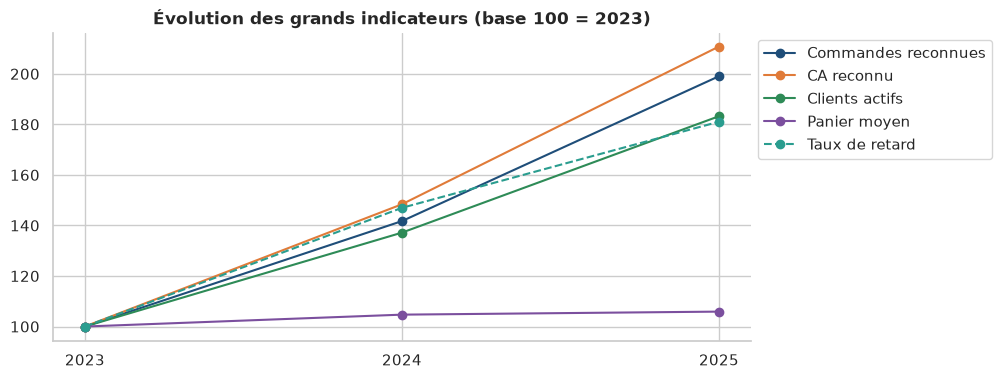

In [13]:
# Les mêmes indicateurs en base 100 (2023 = 100) pour comparer leurs évolutions
base100 = vue_ensemble[["commandes_reconnues", "ca_reconnu_ttc", "clients_actifs", "panier_moyen_ttc", "taux_retard"]]
base100 = (base100 / base100.iloc[0] * 100).rename(columns={
    "commandes_reconnues": "Commandes reconnues", "ca_reconnu_ttc": "CA reconnu", "clients_actifs": "Clients actifs",
    "panier_moyen_ttc": "Panier moyen", "taux_retard": "Taux de retard"})
ax = base100.plot(marker="o", figsize=(9, 4), style=["-", "-", "-", "-", "--"])
ax.set_title("Évolution des grands indicateurs (base 100 = 2023)"); ax.set_xticks([2023, 2024, 2025]); ax.set_xlabel("")
ax.legend(title="", bbox_to_anchor=(1, 1))
montrer("G03_vue_ensemble_base100")

> **Lecture.** En deux ans, le **CA reconnu double** (+111 %, de 3,38 à 7,13 M DT) et les **commandes aussi** (+99 %), avec 83 % de clients actifs en plus ; le **panier moyen** ne progresse que de 6 % (254 → 269 DT) : la croissance vient du volume. Le revers : le **taux de retard** de livraison suit la même pente (+80 %, de 9,6 % à 17,3 %) et la note moyenne baisse légèrement (4,09 → 4,04). Ces deux tendances, croissance et dégradation logistique, se retrouvent dans tous les notebooks thématiques.

## 5. Tables de variables communes (`05_Data`)

Les 4 tables sont construites par `features.py` à partir des vues du DWH et enregistrées en Parquet. Elles servent au **data mining** (`02_Data_Mining`) et au **machine learning** (`03_Machine_Learning`) : chacun relit les mêmes variables avec `features.lire("nom")`.

| Table | 1 ligne = | Utilisée par |
|---|---|---|
| `clients` | 1 client actif à une fin de trimestre (9 photos) | RFM, clustering, ML churn |
| `commandes` | 1 commande, avec la liste de ses articles | association, comportement d'achat |
| `produits_mois` | 1 produit × 1 mois (ventes, stock, rupture, calendrier) | ML prévision des ventes, ML demande |
| `expeditions` | 1 expédition livrée | ML retard de livraison |

L'analyse des cibles, des fuites de données et de la dérive de ces tables est faite dans `03_Machine_Learning/01_Preparation_Datasets_ML` (préparation au ML séparée de l'EDA).

In [14]:
tables = {
    "clients": features.table_clients(p),
    "commandes": features.table_commandes(p),
    "produits_mois": features.table_produits_mois(p, vues),
    "expeditions": features.table_expeditions(p, vues),
}
for nom, table in tables.items():
    features.sauvegarder(table, nom)

  clients                  43 488 lignes x 28 colonnes -> clients.parquet


  commandes                66 268 lignes x 33 colonnes -> commandes.parquet
  produits_mois            18 357 lignes x 25 colonnes -> produits_mois.parquet
  expeditions              58 776 lignes x 21 colonnes -> expeditions.parquet


In [15]:
# Résumé des 4 tables : lignes, colonnes, période couverte
# et, pour les tables qui portent une cible de ML, le taux de cette cible par période
cibles = {"clients": "churn", "expeditions": "en_retard"}
resume = pd.DataFrame([{"table": nom, "lignes": len(t), "colonnes": t.shape[1],
                        "lignes apprentissage": int((t["periode"] == "apprentissage").sum()),
                        "lignes test": int((t["periode"] == "test").sum()),
                        "cible": cibles.get(nom, "—"),
                        "taux cible apprentissage": t.loc[t["periode"] == "apprentissage", cibles[nom]].mean() if nom in cibles else None,
                        "taux cible test": t.loc[t["periode"] == "test", cibles[nom]].mean() if nom in cibles else None}
                       for nom, t in tables.items()])
cfg.exporter_table(resume, "G04_tables_variables", index=False)
resume

  ✔ ana.eda_g04_tables_variables                      4 lignes


,table,lignes,colonnes,lignes apprentissage,lignes test,cible,taux cible apprentissage,taux cible test
0,clients,43488,28,24074,19414,churn,0.617,0.643
1,commandes,66268,33,36233,30035,—,NaN,NaN
2,produits_mois,18357,25,11365,6992,—,NaN,NaN
3,expeditions,58776,21,32186,26590,en_retard,0.122,0.173


### Métadonnées : dictionnaire des variables et lignage

- `05_Data/metadata/Dictionnaire_Variables.xlsx` : chaque variable, son type, sa description, ses vues sources, sa règle de calcul, et **à quel moment elle est connue** (pour éviter les fuites de données) ;
- `05_Data/metadata/Data_Lineage.xlsx` : le chemin des données, des fichiers sources jusqu'aux notebooks qui les utilisent.

In [16]:
features.exporter_metadonnees(tables, cfg.DOSSIER_METADATA)
features.dictionnaire_variables().head(10)

Classeur enregistré : 05_Data\metadata\Dictionnaire_Variables.xlsx
Classeur enregistré : 05_Data\metadata\Data_Lineage.xlsx


,table,variable,description,vues_bi_sources,regle_de_calcul,connue_a,utilisee_par
0,clients,client_sk,Clé du client dans le DWH,v_dim_client,clé de la version du client,toujours,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
1,clients,date_observation,Fin de trimestre à laquelle le client est phot...,—,dates de temporal_split,—,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
2,clients,recence_j,Jours depuis la dernière commande,v_fact_commandes,date_observation - date de la dernière command...,date d'observation,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
3,clients,anciennete_j,Jours depuis la première commande,v_fact_commandes,date_observation - date de la première commande,date d'observation,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
4,clients,frequence,Nombre de commandes passées,v_fact_commandes,nombre de commandes (commandes hors échec de p...,date d'observation,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
5,clients,montant_reconnu_ttc,CA reconnu TTC cumulé du client,"v_fact_commandes, v_dim_statut_commande",somme de montant_total_ttc des commandes abouties,date d'observation,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
6,clients,panier_moyen_ttc,Montant moyen d'une commande,v_fact_commandes,moyenne de montant_total_ttc,date d'observation,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
7,clients,nb_articles_moyen,Nombre moyen d'articles par commande,v_fact_commandes,moyenne de nb_articles,date d'observation,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
8,clients,part_mobile,Part des commandes passées sur l'application m...,"v_fact_commandes, v_dim_canal",commandes canal = application_mobile / commandes,date d'observation,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."
9,clients,part_paiement_livraison,Part des commandes payées à la livraison,"v_fact_commandes, v_dim_mode_paiement",commandes paiement_a_la_livraison / commandes,date d'observation,"02_Data_Mining (RFM, clustering) ; 03_Machine_..."


> **Lecture.** Les 4 tables sont construites à partir des vues du DWH et enregistrées dans `05_Data/features` : **43 488** photos de clients (11 114 clients différents sur 9 fins de trimestre), **66 268** commandes, **18 357** couples produit × mois (595 produits) et **58 776** expéditions livrées. Chaque table a une colonne `periode` (apprentissage 2023-2024 / test 2025). Le dictionnaire décrit chaque colonne réellement présente, avec le moment où elle est connue. Les deux cibles déjà présentes sont bien équilibrées pour le ML : **churn** 61,7 % en apprentissage et 64,3 % en test, **retard** 12,2 % puis 17,3 % (la dérive de 2025).

## 6. Synthèse

| Contrôle | Résultat |
|---|---|
| C01-C02 : connexion et 23 vues complètes | voir section 1 |
| C03-C07 : 5 totaux validés (SQL = Python = PV) | voir section 2 |
| C08 : intégrité (16 relations) | voir section 3.1 |
| C09 : unicité (6 clés) | voir section 3.2 |
| C10 : membres techniques | voir section 3.3 |
| C11 : valeurs manquantes expliquées | voir section 3.4 |

> **Lecture.** **Tous les contrôles sont au vert** : 23 vues complètes, 5 totaux identiques au PV, 16 relations sans orpheline, 6 clés sans doublon, membres inconnus rares, vides expliqués. L'EDA thématique (notebooks 02 à 06) peut s'appuyer sur ces données sans réserve. Les deux grandes tendances à suivre sont posées : **une croissance portée par le volume** et **une logistique qui se dégrade**.

In [17]:
chargement.fermer_connexion()

Connexion fermée.
